In [2]:
import pandas as pd

In [3]:
# 1. Install required libraries in Colab
!pip install pymysql sqlalchemy

In [ ]:
!pip install jupyter-ai

In [5]:
# 2. Import packages
import pandas as pd
from sqlalchemy import create_engine
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
# 3. Create connection engine
# Replace username, password, host, port, and db_name with your actual MySQL credentials
# (If using localhost tunnel, replace localhost with your tunnel URL/IP)
db_user = 'root'
db_password = 'Afiq-2004'
db_host = 'localhost'
db_port = '3306'
db_name = 'streetwear_db' # or your streetwear db name

In [7]:
connection_str = f'mysql+pymysql://{db_user}:{db_password}@{db_host}:{db_port}/{db_name}'
engine = create_engine(connection_str)

In [12]:
# 4. Pull data into a Pandas DataFrame
query = "SELECT * FROM streetwear_sales;" 
df = pd.read_sql(query, con=engine)

In [13]:
df

,date,product_name,product_type,brand,gender,category,country,quantity,unit_price_usd,amount_usd,payment_mode
0,2022-05-27,Fear of God Essentials Tee,T-shirt,Essentials,Unisex,Limited Edition,Japan,5,141.82,709.10,Card
1,2022-08-22,Yeezy Boost 350,Sneakers,Adidas,Unisex,Streetwear,USA,2,267.34,534.68,Cash on Delivery
2,2022-04-03,Nike Dunk Low,Sneakers,Nike,Women,Limited Edition,Germany,1,292.00,292.00,Cash on Delivery
3,2022-07-13,Nike Tech Fleece,Hoodie,Nike,Men,Limited Edition,USA,4,245.44,981.76,Cash on Delivery
4,2022-08-25,Jordan 1 High,Sneakers,Nike,Women,Casual,Australia,2,184.51,369.02,Cash on Delivery
...,...,...,...,...,...,...,...,...,...,...,...
348,2022-04-08,Jordan 1 High,Sneakers,Nike,Men,Casual,India,5,94.25,471.25,Wallet
349,2022-08-03,Nike Tech Fleece,Hoodie,Nike,Women,Casual,Germany,5,259.00,1295.00,Card
350,2022-05-05,Puma Joggers,Joggers,Puma,Women,Casual,Germany,4,299.73,1198.92,Cash on Delivery
351,2022-05-19,Adidas Ultraboost,Sneakers,Adidas,Men,Casual,Canada,5,71.26,356.30,Cash on Delivery


In [14]:
query1 = """SELECT product_type, brand, ROUND(SUM(amount_usd),2) AS total_revenue_usd
FROM streetwear_sales
GROUP BY product_type, brand
ORDER BY total_revenue_usd DESC;"""

df1 = pd.read_sql(query1, con=engine)
df1

,product_type,brand,total_revenue_usd
0,Sneakers,Nike,44728.46
1,Sneakers,Adidas,36858.43
2,Hoodie,Off-White,24214.82
3,Hoodie,Nike,23247.12
4,Joggers,Puma,21342.02
5,Hoodie,Supreme,15647.51
6,Cap,New Era,13915.46
7,T-shirt,Essentials,13149.25


### 3) How does prices compare to revenue? does higher prices = higher revenue or lower prices = lower revenue or something else?

3.1 Summary statistics by product type

In [15]:
# 1. Calculate summary statistics grouped by product type
summary_stats = df.groupby('product_type').agg(
    Avg_Unit_Price=('unit_price_usd', 'mean'), # update column name if yours differs
    Median_Unit_Price=('unit_price_usd', 'median'),
    Max_Unit_Price=('unit_price_usd', 'max'),
    Avg_Revenue=('amount_usd', 'mean'),
    Total_Revenue=('amount_usd', 'sum'),
    Total_Quantity=('quantity', 'sum')
).reset_index()

# Round for neatness
summary_stats = summary_stats.round(2)
summary_stats

,product_type,Avg_Unit_Price,Median_Unit_Price,Max_Unit_Price,Avg_Revenue,Total_Revenue,Total_Quantity
0,Cap,166.12,152.54,295.25,479.84,13915.46,88
1,Hoodie,164.94,162.36,296.56,521.57,63109.45,378
2,Joggers,184.83,194.31,299.73,520.54,21342.02,116
3,Sneakers,182.75,185.10,299.30,599.90,81586.89,435
4,T-shirt,170.34,158.26,271.18,505.74,13149.25,80


3.2 Check correlation between price and revenue

In [16]:
# Check correlation matrix
correlation = df[['unit_price_usd', 'quantity', 'amount_usd']].corr()
print("Correlation Matrix:")
print(correlation)

Correlation Matrix:
                unit_price_usd  quantity  amount_usd
unit_price_usd        1.000000  0.043918    0.662852
quantity              0.043918  1.000000    0.714649
amount_usd            0.662852  0.714649    1.000000


3.3 Scatter Plot Unit Price vs Revenue

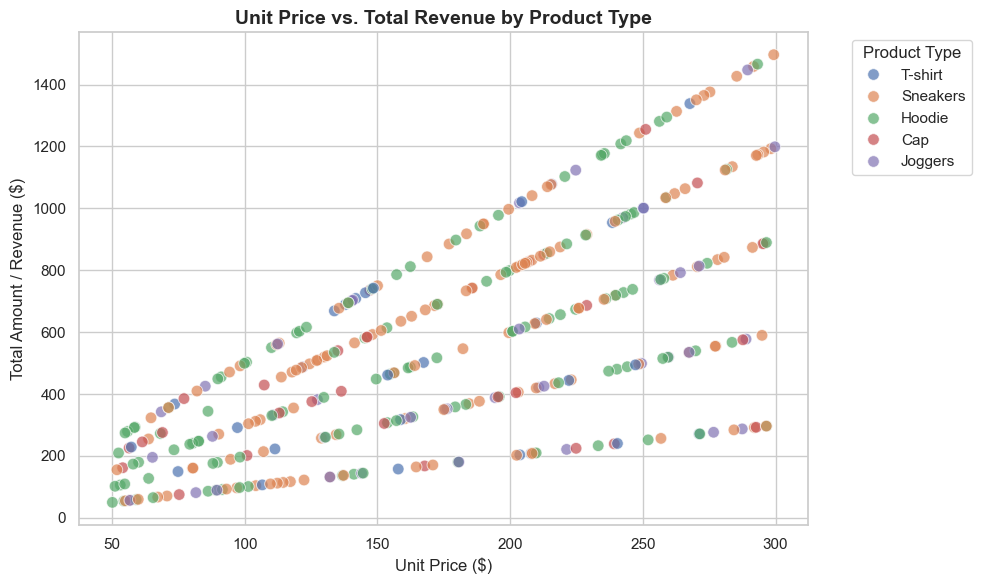

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='unit_price_usd',
    y='amount_usd',
    hue='product_type',
    palette='deep',
    alpha=0.7,
    s=70
)

plt.title('Unit Price vs. Total Revenue by Product Type', fontsize=14, fontweight='bold')
plt.xlabel('Unit Price ($)', fontsize=12)
plt.ylabel('Total Amount / Revenue ($)', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Product Type')
plt.tight_layout()
plt.show()

### 4) Temporal sales? time series chart for sales. are there any peaks or patterns of sales by month/quarter?


4.1 Total revenue by months

In [23]:
# Replace 'date' with your actual date column name if it differs
df['date'] = pd.to_datetime(df['date'])

# 2. Extract Year-Month for trend analysis
df['month'] = df['date'].dt.to_period('M')
df['quarter'] = df['date'].dt.to_period('Q')

# 3. Group by month to get monthly revenue
monthly_revenue = df.groupby('month')['amount_usd'].sum().reset_index()
# Convert Period back to timestamp/string for clean plotting
monthly_revenue['month'] = monthly_revenue['month'].astype(str)

print(monthly_revenue.head(12))

     month  amount_usd
0  2022-01    23067.92
1  2022-02    20393.54
2  2022-03    29043.18
3  2022-04    17176.88
4  2022-05    20397.44
5  2022-06    26089.22
6  2022-07    32073.43
7  2022-08    24861.46


4.2 Time-series chart

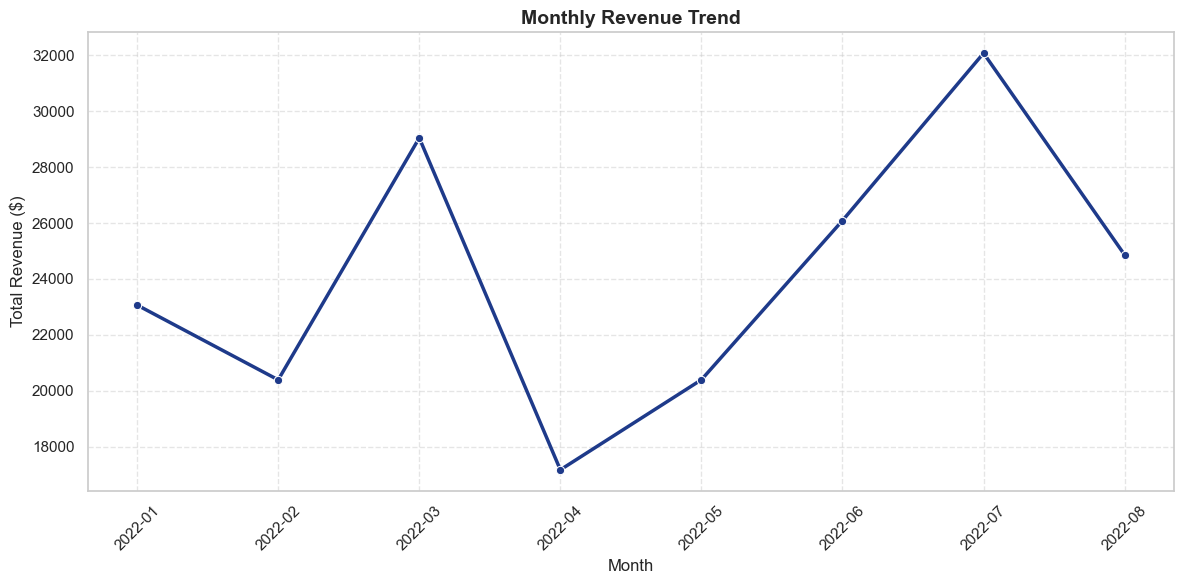

In [24]:
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=monthly_revenue,
    x='month',
    y='amount_usd',
    marker='o',
    color='#1E3A8A', # Deep navy blue
    linewidth=2.5
)

plt.title('Monthly Revenue Trend', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Revenue ($)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()